# Project: Recreate Graphs using Matplotlib
*Codecademy: Analyze Financial Data with Python / Visualizing Finance Data - lesson 2 project*

A high school math teacher wants to see patterns in their classes' results. Codecademy shows a finished chart for each task; the job is to rebuild it from scratch with the plot types from [02_different_plot_types](02_different_plot_types.ipynb).

Every chart is saved to `charts/` and collected in this folder's [README](README.md).

In [1]:
from matplotlib import pyplot as plt

CHARTS = 'charts/'

## 1. Bar Chart with Error
**Task:** final exam averages for 2000-2006 as bars with error bars (cap size 5), figure 10 x 8, axis from -0.5 to 6.5 (x) and 70 to 95 (y), years as tick labels, title and axis labels.

In [2]:
past_years_averages = [82, 84, 83, 86, 74, 84, 90]
years = [2000, 2001, 2002, 2003, 2004, 2005, 2006]
error = [1.5, 2.1, 1.2, 3.2, 2.3, 1.7, 2.4]

My code:

```python
plt.figure(figsize=(10, 8))
plt.bar(range(len(past_years_averages)),past_years_averages,capsize=5, yerr=error)
plt.axis([-0.5,6.5,70,95])
ax = plt.subplot()
ax.set_xticks(range(len(years)))
ax.set_xticklabels(years)
plt.xlabel("Year")
plt.ylabel("Test average")
plt.title("Final Exam Averages")
plt.show()

plt.savefig("my_bar_chart.png")
```

**Mistake: `savefig` after `show` - the saved file is blank.** `plt.show()` displays the figure and then clears it, so `savefig` saves an empty sheet. Codecademy may still pass it, but locally the PNG comes out white. **Save, then show.**

Fixed:

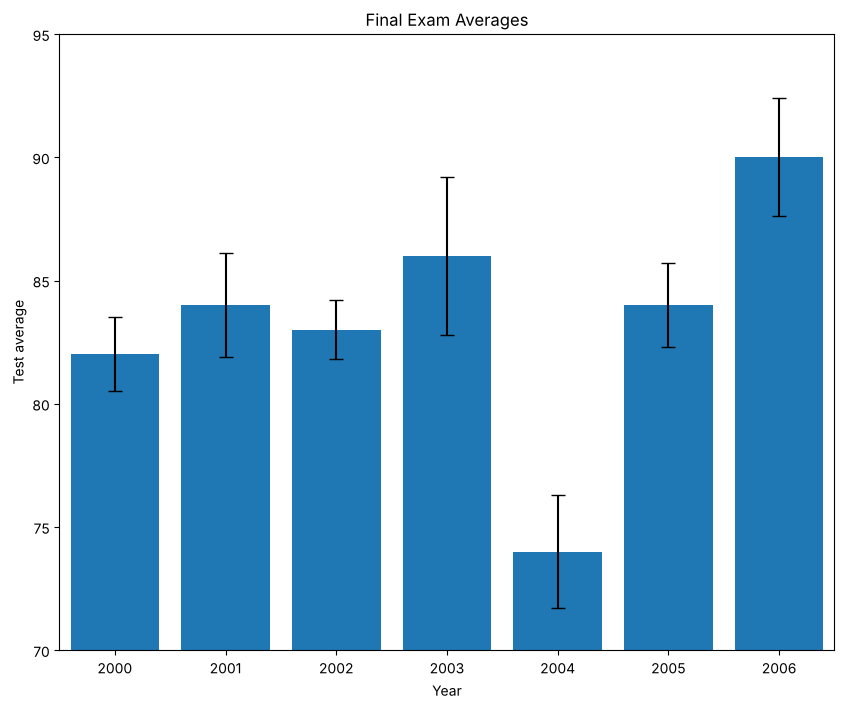

In [3]:
plt.figure(figsize=(10, 8))
plt.bar(range(len(past_years_averages)), past_years_averages, yerr=error, capsize=5)
plt.axis([-0.5, 6.5, 70, 95])

ax = plt.subplot()
ax.set_xticks(range(len(years)))
ax.set_xticklabels(years)

plt.title("Final Exam Averages")
plt.xlabel("Year")
plt.ylabel("Test average")

plt.savefig(CHARTS + 'recreate_01_bar_chart_error.png')   # save first
plt.show()                                                # then show

**Truncated axis:** the task makes the y-axis start at **70** - against the rule from [section 1 of the lesson](02_different_plot_types.ipynb) that bars start at 0. A bar's height *is* its value, so with the axis cut off 2004 (74) looks like a collapse and 2006 (90) like a huge jump - the real spread is 74 to 90 out of 100. Same data, honest axis:

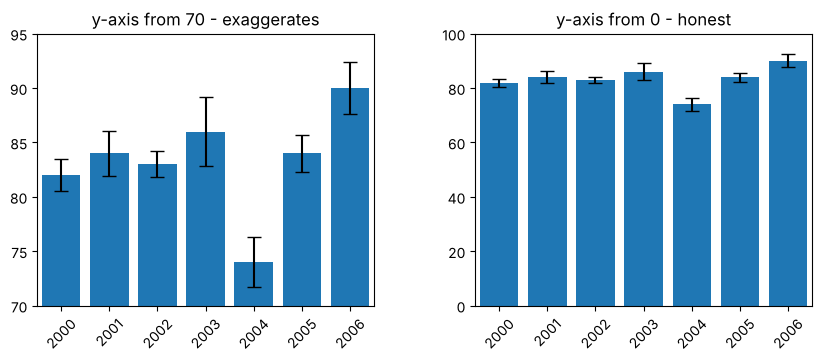

In [4]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.bar(range(len(years)), past_years_averages, yerr=error, capsize=5)
plt.axis([-0.5, 6.5, 70, 95])
plt.xticks(range(len(years)), years, rotation=45)
plt.title('y-axis from 70 - exaggerates')

plt.subplot(1, 2, 2)
plt.bar(range(len(years)), past_years_averages, yerr=error, capsize=5)
plt.axis([-0.5, 6.5, 0, 100])
plt.xticks(range(len(years)), years, rotation=45)
plt.title('y-axis from 0 - honest')

plt.subplots_adjust(wspace=0.3, bottom=0.2)
plt.savefig(CHARTS + 'recreate_01b_truncated_vs_honest.png')
plt.show()

- Style: a space after each comma - `past_years_averages, capsize=5`. Runs either way, but it's the convention.
- If the zoom is really needed, use dots or a line with error bars instead of bars - a dot's position doesn't pretend to be a quantity starting at 0.

## 2. Side By Side Bars
**Task:** average test scores per unit for students from Middle School A and B, side by side - x positions with `create_x`, ticks in the middle of each pair, unit names as labels, legend, title and axis labels, figure 10 x 8.

In [5]:
unit_topics = ['Limits', 'Derivatives', 'Integrals', 'Diff Eq', 'Applications']
middle_school_a = [80, 85, 84, 83, 86]
middle_school_b = [73, 78, 77, 82, 86]

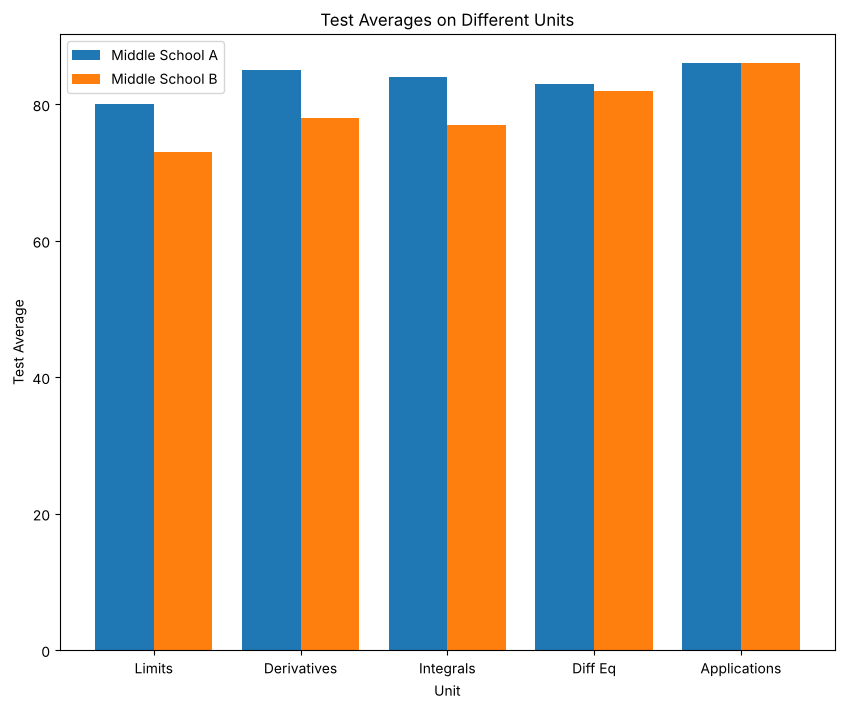

In [6]:
def create_x(t, w, n, d):
    return [t*x + w*n for x in range(d)]
# Make your chart here
#n = 1    # This is our first dataset (out of 2)
#t = 2    # Number of datasets
#d = 5    # Number of sets of bars
#w = 0.8  # Width of each bar
school_a_x = create_x(2,0.8,1,5)
school_b_x = create_x(2,0.8,2,5)

plt.figure(figsize=(10,8))

ax = plt.subplot()

ax.bar(school_a_x,middle_school_a)
ax.bar(school_b_x,middle_school_b)

middle_x = [(a+b)/2 for a,b in zip(school_a_x,school_b_x)]

ax.set_xticks(middle_x)
ax.set_xticklabels(unit_topics)

ax.legend(["Middle School A", "Middle School B"])

ax.set_title('Test Averages on Different Units')
ax.set_xlabel('Unit')
ax.set_ylabel("Test Average")

plt.savefig(CHARTS + 'recreate_02_side_by_side.png')
plt.show()

### `plt.` style vs `ax.` style
Here everything goes through `ax` - not only the ticks. That's how most professional code looks: every command says *which* chart it changes, which matters as soon as there are subplots. The only catch - some names differ:

| `plt.` style | `ax.` style |
|---|---|
| `plt.title()` | `ax.set_title()` |
| `plt.xlabel()` / `plt.ylabel()` | `ax.set_xlabel()` / `ax.set_ylabel()` |
| `plt.axis([...])` | `ax.set_xlim()` / `ax.set_ylim()` |
| `plt.bar()`, `plt.legend()` | `ax.bar()`, `ax.legend()` (same names) |

### `middle_x` with `zip`

```text
school_a_x:  0.8   2.8   4.8 ...
school_b_x:  1.6   3.6   5.6 ...
             \_/   \_/
middle_x:    1.2   3.2   5.2 ...   (a + b) / 2
```

Bars are centred on their x-values, so the midpoint lands exactly where each pair touches - where the label belongs. `zip` pairs the two lists element by element, like walking down two columns side by side (same trick as the three-layer stacked bars in [section 4 of the lesson](02_different_plot_types.ipynb)).

### Readability: name the arguments
`create_x(2,0.8,1,5)` works, but in six months nobody remembers which number is which. Name them - then the commented-out template isn't needed:

```python
school_a_x = create_x(t=2, w=0.8, n=1, d=5)
school_b_x = create_x(t=2, w=0.8, n=2, d=5)
```

Named arguments can go in any order and make the code explain itself - same as R's `create_x(t = 2, w = 0.8, ...)`.

## 3. Stacked Bars
**Task:** how many students got an A, B, C, D or F in each unit - five layers stacked on top of each other, figure 10 x 8, unit names as tick labels, title and axis labels. Codecademy introduces `np.add` for the bottoms.

In [7]:
import numpy as np

unit_topics = ['Limits', 'Derivatives', 'Integrals', 'Diff Eq', 'Applications']
As = [6, 3, 4, 3, 5]
Bs = [8, 12, 8, 9, 10]
Cs = [13, 12, 15, 13, 14]
Ds = [2, 3, 3, 2, 1]
Fs = [1, 0, 0, 3, 0]

x = range(5)   # given by the exercise

My code:

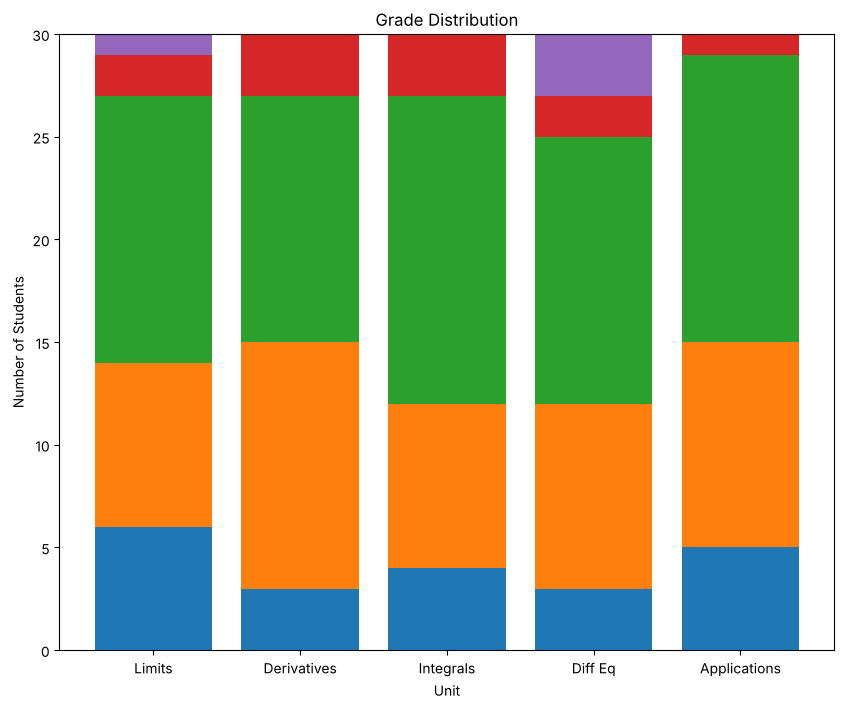

In [8]:
c_bottom = np.add(As, Bs)
#create d_bottom and f_bottom here
d_bottom = np.add(c_bottom, Cs)
f_bottom = np.add(d_bottom, Ds)

#create your plot here
plt.figure(figsize=(10,8))

plt.bar(range(len(As)),
 As)

plt.bar(range(len(Bs)),
  Bs,
  bottom = As)


plt.bar(range(len(Cs)),
  Cs,
  bottom = c_bottom)

plt.bar(range(len(Ds)),
  Ds,
  bottom = d_bottom)

plt.bar(range(len(Fs)),
 Fs,
 bottom = f_bottom)

ax = plt.subplot()
ax.set_xticks(range(len(unit_topics)))
ax.set_xticklabels(unit_topics)

plt.title("Grade Distribution")
plt.xlabel("Unit")
plt.ylabel("Number of Students")

plt.savefig(CHARTS + 'recreate_03_stacked_bars.png')




plt.show()

### How the bottoms build up
Each layer's floor = everything below it added together:

```text
Limits:                          bottom for this layer
  F  1   +--+  30   f_bottom = d_bottom + Ds = 27 + 2 = 29
  D  2   +--+  29   d_bottom = c_bottom + Cs = 14 + 13 = 27
  C 13   +--+  27   c_bottom = As + Bs      = 6 + 8   = 14
         |  |
  B  8   +--+  14   bottom = As                       = 6
  A  6   +--+   6   (no bottom -> starts at 0)
         +--+   0
```

Chaining `np.add(c_bottom, Cs)` instead of re-adding all four lists: each new floor = previous floor + one layer.

### Why `np.add` and not `+`?
On plain Python lists, `+` **glues** the lists together instead of adding the numbers:

```python
As + Bs          # -> [6, 3, 4, 3, 5, 8, 12, 8, 9, 10]   10 items
np.add(As, Bs)   # -> [14, 15, 12, 12, 15]               element by element
```

`np.add` works like `As + Bs` in R. Three ways to add two lists element by element so far:
- list comprehension: `[a + b for a, b in zip(As, Bs)]`
- `np.add(As, Bs)`
- NumPy arrays: `np.array(As) + np.array(Bs)`

### Two small things
- `x = range(5)` is given by the exercise but never used - using `x` in every `plt.bar` saves writing `range(len(...))` five times.
- **No legend** - a reader can't tell which colour is A and which is F. Add `plt.legend(['A', 'B', 'C', 'D', 'F'])` after the bars.

### Faster way: one loop
Five almost identical `plt.bar` blocks become one loop that keeps track of the floor itself:

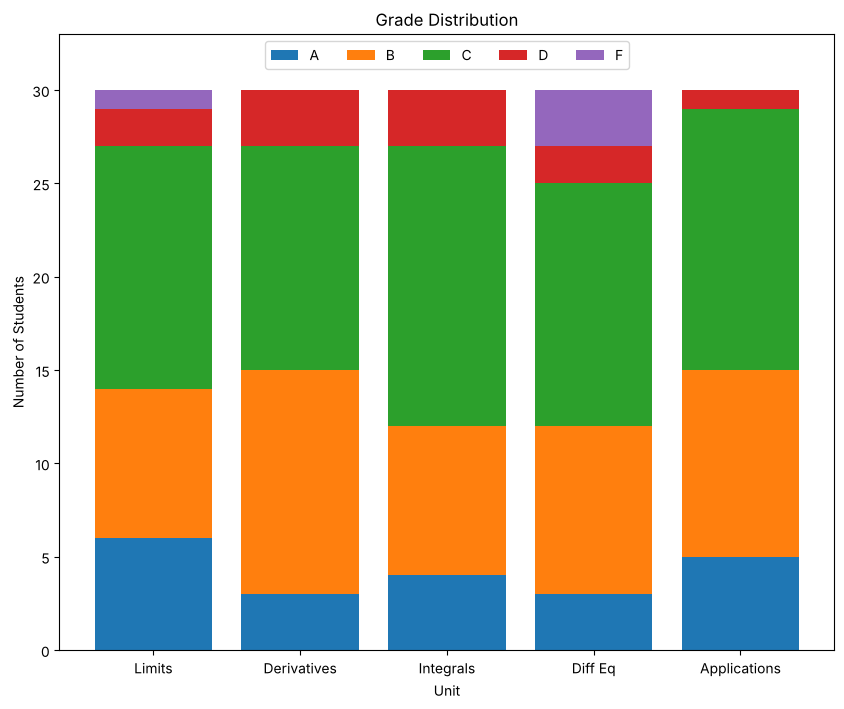

In [9]:
plt.figure(figsize=(10, 8))

x = range(len(unit_topics))
bottom = np.zeros(len(unit_topics))          # first floor: 0 everywhere

for grades, label in zip([As, Bs, Cs, Ds, Fs], ['A', 'B', 'C', 'D', 'F']):
    plt.bar(x, grades, bottom=bottom, label=label)
    bottom = bottom + grades                 # next layer starts where this one ends

ax = plt.subplot()
ax.set_xticks(x)
ax.set_xticklabels(unit_topics)

plt.legend(ncol=5, loc='upper center')     # one row across the top
plt.ylim(0, 33)                             # a bit of headroom so it doesn't cover the bars
plt.title("Grade Distribution")
plt.xlabel("Unit")
plt.ylabel("Number of Students")

plt.savefig(CHARTS + 'recreate_03b_stacked_bars_loop.png')
plt.show()

```text
round   grades   label   bottom before        bottom after (+ grades)
1       As       'A'     [0, 0, 0, 0, 0]      [6, 3, 4, 3, 5]
2       Bs       'B'     [6, 3, 4, 3, 5]      [14, 15, 12, 12, 15]
3       Cs       'C'     [14, 15, 12, 12, 15] [27, 27, 27, 25, 29]
4       Ds       'D'     [27, 27, 27, 25, 29] [29, 30, 30, 27, 30]
5       Fs       'F'     [29, 30, 30, 27, 30] (not needed anymore)
```

- `np.zeros(5)` - a NumPy array of five 0s. Because `bottom` is a NumPy array, `bottom + grades` adds element by element (on two lists it would glue them).
- `zip(...)` walks through the grades and their labels as pairs.
- `label=` inside each `plt.bar` - then `plt.legend()` needs no list; the names can't get out of order.
- A sixth grade would only change the two lists, not the code.
- The bars fill the whole chart, so with plain `plt.legend()` matplotlib finds no empty spot and puts the legend on top of the bars. `ncol=5` lays it out in one row, `plt.ylim(0, 33)` adds empty space above the bars for it.

**Finance:** a bond portfolio split by credit rating (AAA, AA, A, BBB, junk) for each fund - bar height = total number of bonds, layers = how risky the mix is.

## 4. Two Histograms on a Plot
**Task:** final exam scores of the 1st vs 2nd year of teaching as two normalized histograms (12 bins) on one chart - outlines only (`histtype='step'`, `linewidth=2`), legend, title and axis labels, figure 10 x 8.

In [10]:
exam_scores1 = [62.58, 67.63, 81.37, 52.53, 62.98, 72.15, 59.05, 73.85, 97.24, 76.81, 89.34, 74.44, 68.52, 85.13, 90.75, 70.29, 75.62, 85.38, 77.82, 98.31, 79.08, 61.72, 71.33, 80.77, 80.31, 78.16, 61.15, 64.99, 72.67, 78.94]
exam_scores2 = [72.38, 71.28, 79.24, 83.86, 84.42, 79.38, 75.51, 76.63, 81.48,78.81,79.23,74.38,79.27,81.07,75.42,90.35,82.93,86.74,81.33,95.1,86.57,83.66,85.58,81.87,92.14,72.15,91.64,74.21,89.04,76.54,81.9,96.5,80.05,74.77,72.26,73.23,92.6,66.22,70.09,77.2]

My code:

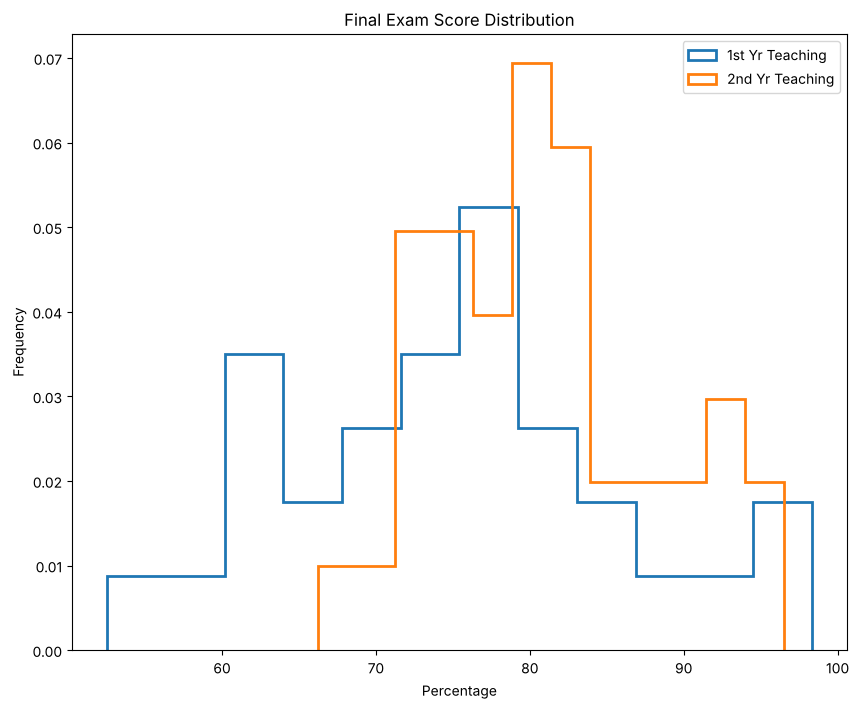

In [11]:
plt.figure(figsize=(10,8))

plt.hist(exam_scores1, bins = 12, density = True, histtype = 'step', linewidth = 2)
plt.hist(exam_scores2, bins = 12, density = True, histtype = 'step', linewidth = 2)

plt.legend(["1st Yr Teaching", "2nd Yr Teaching"])
plt.xlabel("Percentage")
plt.ylabel("Frequency")
plt.title("Final Exam Score Distribution")

plt.savefig(CHARTS + 'recreate_04_two_histograms.png')

plt.show()

- `density=True` - the classes have different sizes (30 vs 40 students), so we compare **shares**, not counts.
- `histtype='step'` + `linewidth=2` - outlines only, thick enough to see both.

### The two histograms have different bins
Without `range=`, each `plt.hist` builds its 12 bins from its **own** lowest and highest score:

| | lowest | highest | 12 bins -> each bin is |
|---|---|---|---|
| year 1 | 52.5 | 98.3 | **3.8 points** wide |
| year 2 | 66.2 | 96.5 | **2.5 points** wide |

The steps don't line up, and year 2's narrower bins make its peaks look taller. Same window for both - 10 bins of exactly 5 points (50-55, 55-60 ...):

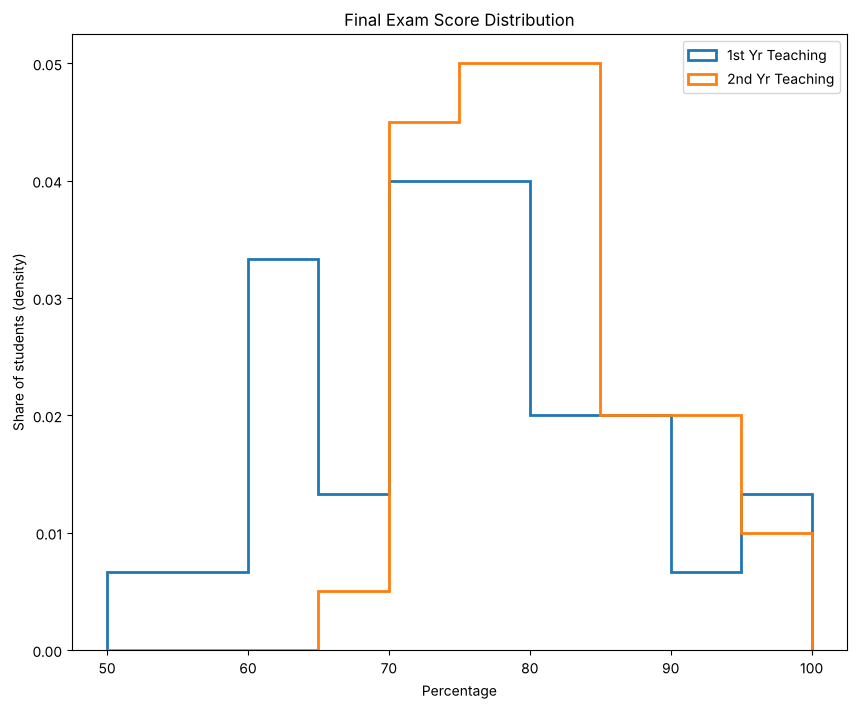

In [12]:
plt.figure(figsize=(10, 8))

plt.hist(exam_scores1, range=(50, 100), bins=10, density=True, histtype='step', linewidth=2)
plt.hist(exam_scores2, range=(50, 100), bins=10, density=True, histtype='step', linewidth=2)

plt.legend(["1st Yr Teaching", "2nd Yr Teaching"])
plt.xlabel("Percentage")
plt.ylabel("Share of students (density)")
plt.title("Final Exam Score Distribution")

plt.savefig(CHARTS + 'recreate_04b_two_histograms_same_bins.png')
plt.show()

### What the chart says

| | students | average | spread (std) | lowest |
|---|---|---|---|---|
| 1st year | 30 | 75.0 | 11.0 | 52.5 |
| 2nd year | 40 | 80.7 | 7.3 | 66.2 |

The 2nd-year class scores higher on average **and** is more bunched together - more consistent, not just better.

- **y-label:** the target chart says "Frequency", but with `density=True` it isn't a count anymore - "Density" or "Share of students" is more accurate.
- **Style:** `bins=12`, not `bins = 12` - no spaces around `=` inside a function call.

**Finance:** the same chart with two funds' monthly returns - a narrower histogram means lower volatility, the same "more consistent" story as year 2.

## 5. Labeled Pie Chart
**Task:** which topic students find hardest, as a pie chart - figure 10 x 8, equal axes, `unit_topics` as slice labels, percentages rounded to whole numbers, title "Hardest Topics".

In [13]:
unit_topics = ['Limits', 'Derivatives', 'Integrals', 'Diff Eq', 'Applications']
num_hardest_reported = [1, 3, 10, 15, 1]

My code:

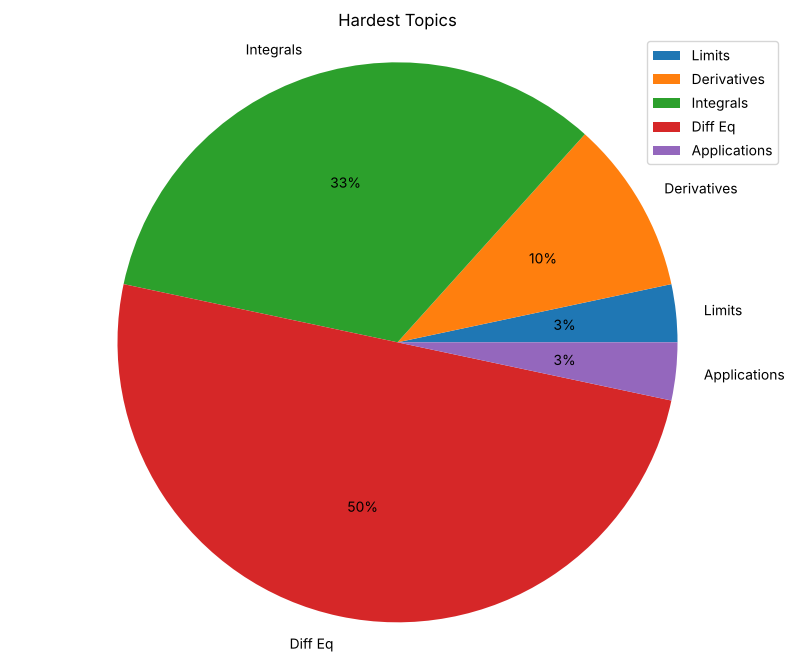

In [14]:
plt.figure(figsize=(10,8))
plt.pie(num_hardest_reported, autopct='%d%%', labels = unit_topics)
plt.axis('equal')
plt.legend(unit_topics)
plt.title("Hardest Topics")
plt.savefig(CHARTS + 'recreate_05b_mistake_pie_double_labels.png')
plt.show()



plt.show()

### My mistakes

**1. Names twice - `labels=` and a legend (repeat of [lesson section 8](02_different_plot_types.ipynb)).** The task only asks for labels on the slices; `plt.legend(unit_topics)` repeats every name. Pick one - here `labels=` is the better choice: only 5 short names.

**2. `%d` cuts off, it doesn't round.** The task says "rounded to the nearest int", but `%d` just drops the decimals:

| share | `'%d%%'` | `'%.0f%%'` |
|---|---|---|
| 33.3 | 33% | 33% |
| 66.7 | **66%** | **67%** |

With this data it makes no difference (all shares are x.0 or x.3), but with other numbers `%d` is silently 1 off. `'%.0f%%'` really rounds.

**3. `plt.show()` twice** - the second one shows an empty figure. Leftover from the template - delete it.

Fixed:

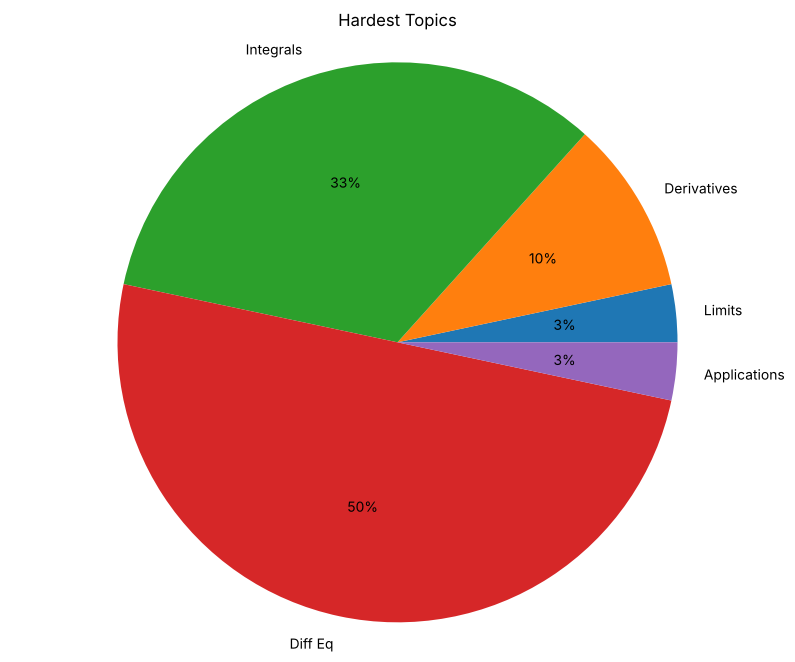

In [15]:
plt.figure(figsize=(10, 8))
plt.pie(num_hardest_reported, labels=unit_topics, autopct='%.0f%%')
plt.axis('equal')
plt.title("Hardest Topics")
plt.savefig(CHARTS + 'recreate_05_pie.png')
plt.show()

- **Rounding again:** the slices add up to 3 + 10 + 33 + 50 + 3 = **99%** - rounded shares rarely sum to exactly 100.
- **What it says:** Diff Eq (50%) and Integrals (33%) = 83% of all "hardest" votes - where a teacher would spend extra time.
- **Why a pie works here:** every student picked exactly one topic, so the parts add up to a real whole (30 students). That's the test for any pie - in finance: portfolio weights, revenue by product line.

## 6. Line with Shaded Error
**Task:** final exam scores (x) against the hours students say they studied (y) as a line (`linewidth=2`), with a ±20% shaded band for the self-reported hours (`alpha=0.2`), figure 10 x 8, title and axis labels.

In [16]:
hours_reported =[3, 2.5, 2.75, 2.5, 2.75, 3.0, 3.5, 3.25, 3.25,  3.5, 3.5, 3.75, 3.75,4, 4.0, 3.75,  4.0, 4.25, 4.25, 4.5, 4.5, 5.0, 5.25, 5, 5.25, 5.5, 5.5, 5.75, 5.25, 4.75]
exam_scores = [52.53, 59.05, 61.15, 61.72, 62.58, 62.98, 64.99, 67.63, 68.52, 70.29, 71.33, 72.15, 72.67, 73.85, 74.44, 75.62, 76.81, 77.82, 78.16, 78.94, 79.08, 80.31, 80.77, 81.37, 85.13, 85.38, 89.34, 90.75, 97.24, 98.31]

My code:

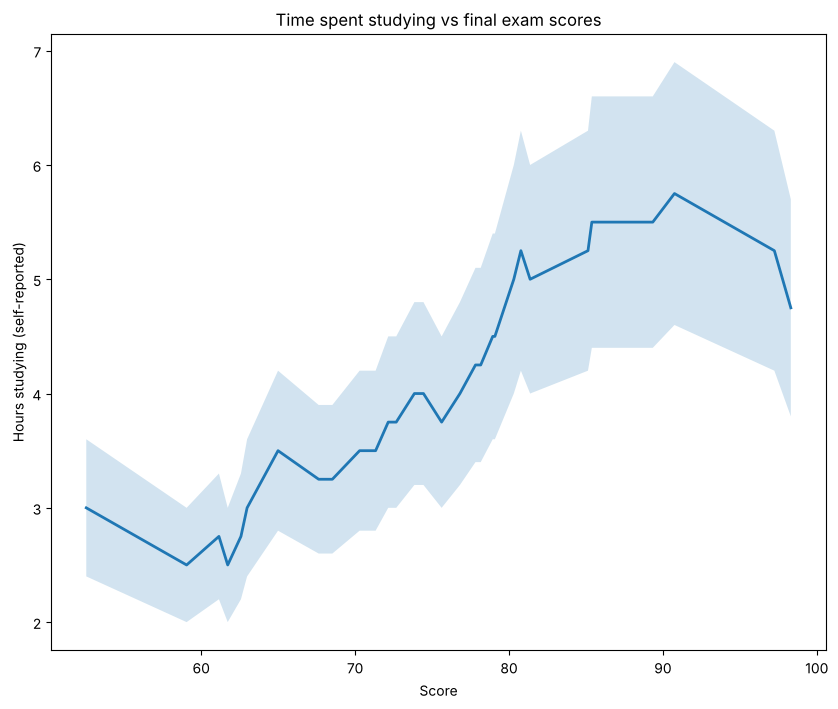

In [17]:
# Create your figure here
plt.figure(figsize=(10,8))

plt.plot(exam_scores, hours_reported, linewidth = 2)

# Create your hours_lower_bound and hours_upper_bound lists here 
hours_lower_bound = [0.8 * i for i in hours_reported]
hours_upper_bound = [1.2 * i for i in hours_reported]

# Make your graph here
plt.fill_between(exam_scores,hours_lower_bound, hours_upper_bound, alpha =0.2)
plt.title('Time spent studying vs final exam scores')
plt.xlabel('Score')
plt.ylabel('Hours studying (self-reported)')

plt.savefig(CHARTS + 'recreate_06_line_shaded_error.png')

plt.show()

- `[0.8 * i for i in hours_reported]` - shorter than the template's `element - (element * 0.2)`, same result.

### My mistake: line first, band second
My own rule from [lesson section 6](02_different_plot_types.ipynb): **band first, line on top.** Here the band is drawn over the line - with `alpha=0.2` it still shows through, but tinted. Swap the two blocks:

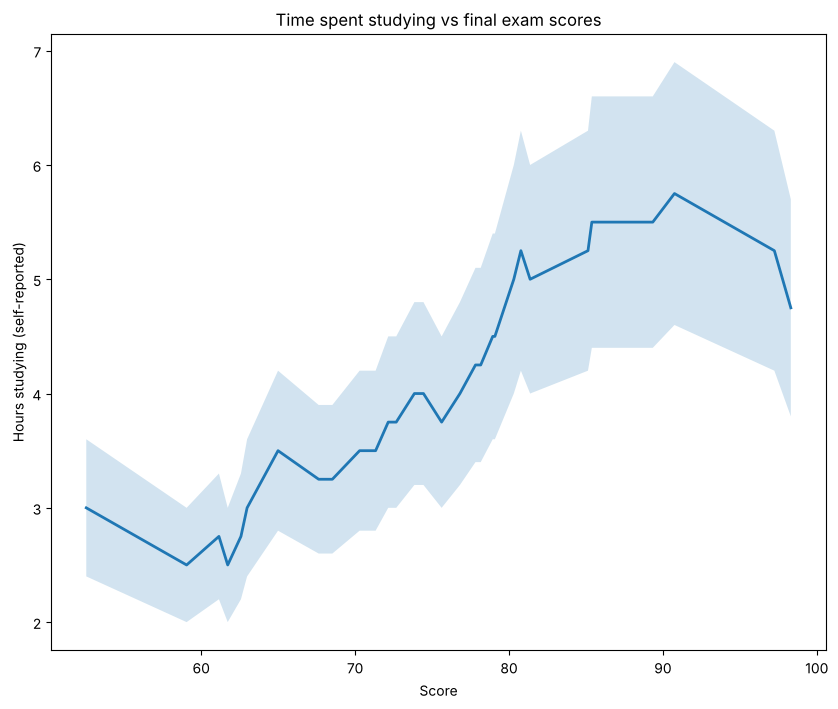

In [18]:
plt.figure(figsize=(10, 8))

plt.fill_between(exam_scores, hours_lower_bound, hours_upper_bound, alpha=0.2)   # band first
plt.plot(exam_scores, hours_reported, linewidth=2)                               # line on top

plt.title('Time spent studying vs final exam scores')
plt.xlabel('Score')
plt.ylabel('Hours studying (self-reported)')

plt.savefig(CHARTS + 'recreate_06b_band_first.png')
plt.show()

### Two questions about the chart itself

**1. Which variable belongs on the x-axis?** Convention: **cause on x, effect on y**. Studying is what you do, the score is the result - so hours on x reads "more hours -> higher score". Same idea as the basics mistake chart "revenue vs time is `plot(time, revenue)`".

**2. Is a line the right chart?** Every point is a *different student*, sorted by score. A line suggests a path from one point to the next (like a price over time), but there is no path from student 7 to student 8 - that's why it zigzags. This is a **relationship** question ("do hours and scores move together?") and the chart for that is a **scatter**:

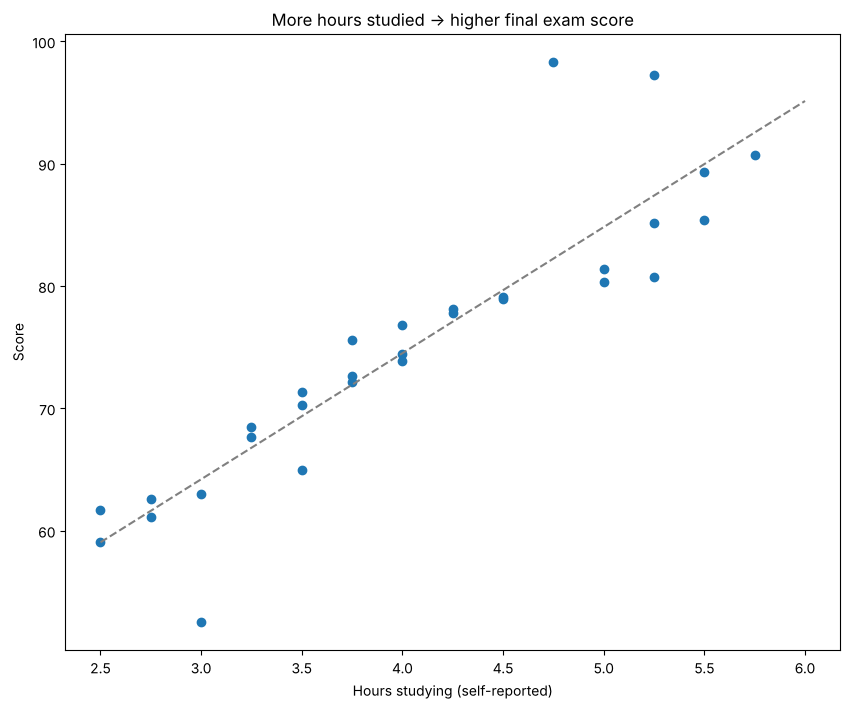

correlation: 0.9
slope: about 10.3 points per extra hour


In [19]:
import numpy as np

slope, intercept = np.polyfit(hours_reported, exam_scores, 1)   # best straight line (preview of Regression)
fit_x = [2.5, 6]
fit_y = [slope * h + intercept for h in fit_x]

plt.figure(figsize=(10, 8))
plt.scatter(hours_reported, exam_scores)
plt.plot(fit_x, fit_y, color='gray', linestyle='--')

plt.title('More hours studied -> higher final exam score')
plt.xlabel('Hours studying (self-reported)')
plt.ylabel('Score')

plt.savefig(CHARTS + 'recreate_06c_scatter_relationship.png')
plt.show()

print('correlation:', round(np.corrcoef(hours_reported, exam_scores)[0, 1], 2))
print('slope: about', round(slope, 1), 'points per extra hour')

- Correlation **0.90** - a strong relationship; roughly **+10 points per extra hour** studied.
- `plt.scatter(x, y)` - dots only, no connecting line (same as `plt.plot(x, y, 'o')`).
- `np.polyfit(x, y, 1)` - the best-fitting straight line (degree 1), returns slope and intercept. This is a first look at the next track, Regression.
- Why not just swap the axes of the line chart? `fill_between` and a line both need the x-values **in order**. Sorted by score, the hours jump back and forth (3, 2.5, 2.75 ...) - with hours on x the line would scribble back and forth.
- **Correlation isn't cause:** students who study more might also be the ones who were already strong.

**Finance:** a stock's daily returns (y) against the market's returns (x) as a scatter with a fitted line - the slope is the stock's **beta**.

**Style:** `linewidth=2`, `alpha=0.2` (no spaces around `=`), and a space after each comma - `exam_scores, hours_lower_bound`.